# Multi-Fidelity CoKriging Comparison

This workbook fits `SurrogateModels.cokriging.CoKriging` on two test functions, using the same sample locations as `MultiFidelityComparison_NN.ipynb`:

- **2D** (`PeaksShifted2`): 400 LF samples, sweeping the number of HF samples from 10 to 200.
- **4D** (`Zhang22Example17`): 800 LF samples, sweeping the number of HF samples from 20 to 400.

Helper functions live in `examples/multi_fidelity_kriging_helpers.py`.

**Settings:** each seed draws its LF and HF samples with `sample_random(n, seed=seed)` for seeds 0 to 2, and the 1000 test points use `sample_random`'s default seed, exactly as in the NN notebook, so the errors compare run for run with `mf_nn_model_comparison_2d.csv` and `mf_nn_model_comparison_4d.csv`. CoKriging uses the default separate means, a nugget of 1e-3, and `x` scaled to [-1, 1] by the function's bounds. HF-only Kriging isn't fit here, because `SingleFidelityComparison_Kriging.ipynb` covers it.

**Seeds:** Kriging's optimizer uses fixed starting points, so a fit is deterministic for given samples. The seed only changes where the samples fall.

**Runtime:** the LF Kriging model is fit once per seed and shared across that seed's runs, because the LF samples don't change with the HF sample count.

**Output:** `cokriging_model_comparison_2d.csv` and `cokriging_model_comparison_4d.csv` have the columns `points_lf, points_hf, model_error, training_time, evaluation_time` with no header, the same as the NN sweep, which is what `load_multi_fidelity_csv_results` in `data_viewer.ipynb` reads. `training_time` includes the shared LF fit. Rerunning appends to the file.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from examples import multi_fidelity_kriging_helpers as mf_kriging_helpers
from examples import single_fidelity_kriging_helpers as kriging_helpers

### 2-Dimensional Dataset

In [2]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kriging_helpers.create_test_points(my_function, n=1000)

Run 2D :: seed 0 :: lf points 400 :: hf points 10 :: error 1.4744038697825261 :: train_time 6.846785600006115 
Run 2D :: seed 0 :: lf points 400 :: hf points 20 :: error 0.9051677103152238 :: train_time 6.859650900005363 


Run 2D :: seed 0 :: lf points 400 :: hf points 30 :: error 0.8042426468585613 :: train_time 6.891941100009717 
Run 2D :: seed 0 :: lf points 400 :: hf points 40 :: error 0.53949882744048 :: train_time 6.86136060001445 


Run 2D :: seed 0 :: lf points 400 :: hf points 50 :: error 0.5860602151242467 :: train_time 6.8875979999720585 
Run 2D :: seed 0 :: lf points 400 :: hf points 60 :: error 0.414959853949052 :: train_time 6.913866299990332 


Run 2D :: seed 0 :: lf points 400 :: hf points 70 :: error 0.2806597061396939 :: train_time 7.139537499984726 


Run 2D :: seed 0 :: lf points 400 :: hf points 80 :: error 0.17504050753421616 :: train_time 7.132348299986916 


Run 2D :: seed 0 :: lf points 400 :: hf points 90 :: error 0.2857271696236795 :: train_time 7.301841099979356 


... (41 outputs left out)

Run 2D :: seed 2 :: lf points 400 :: hf points 170 :: error 0.07518471743407747 :: train_time 8.244604899984552 


Run 2D :: seed 2 :: lf points 400 :: hf points 180 :: error 0.013246123554045324 :: train_time 8.375795699976152 


Run 2D :: seed 2 :: lf points 400 :: hf points 190 :: error 0.058223544420948195 :: train_time 8.328178899973864 


Run 2D :: seed 2 :: lf points 400 :: hf points 200 :: error 0.01766519300310046 :: train_time 8.632638899987796 


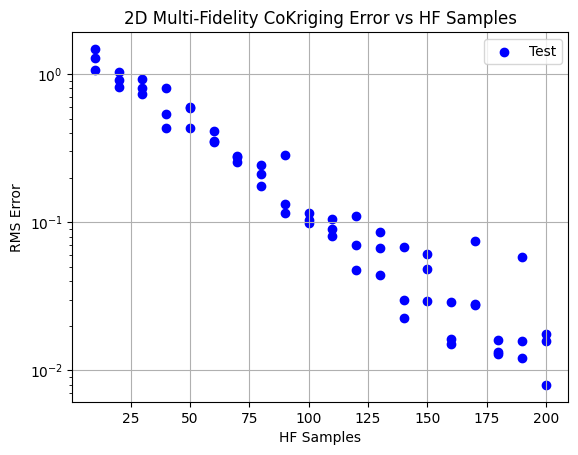

In [3]:
points_2d = []
model_error_2d = []
training_time_2d = []
evaluation_time_2d = []
points_2d, model_error_2d, evaluation_time_2d, training_time_2d = mf_kriging_helpers.generate_cokriging_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    n_lf=400,
    sample_low=10,
    sample_high=201,
    step_size=10,
    seeds=3,
    points=points_2d,
    model_error=model_error_2d,
    training_time=training_time_2d,
    evaluation_time=evaluation_time_2d,
    nugget=1e-3,
    output_file="cokriging_model_comparison_2d.csv",
)
ax = kriging_helpers.plot_error_measure(points_2d, model_error_2d, "2D Multi-Fidelity CoKriging Error vs HF Samples")
ax.set_xlabel("HF Samples")
kriging_helpers.save_plot(ax, "2D_sweep_cokriging")
plt.show()

### 4-Dimensional Dataset

In [4]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = kriging_helpers.create_test_points(my_function, n=1000)

Run 4D :: seed 0 :: lf points 800 :: hf points 20 :: error 3.759001322367538 :: train_time 55.746048100001644 


Run 4D :: seed 0 :: lf points 800 :: hf points 40 :: error 3.6867676970691785 :: train_time 55.91180110001005 


Run 4D :: seed 0 :: lf points 800 :: hf points 60 :: error 3.326829643325752 :: train_time 56.776060900010634 


Run 4D :: seed 0 :: lf points 800 :: hf points 80 :: error 2.9994723435365254 :: train_time 58.77111800000421 


Run 4D :: seed 0 :: lf points 800 :: hf points 100 :: error 3.3005128549898903 :: train_time 59.5927935000218 


Run 4D :: seed 0 :: lf points 800 :: hf points 120 :: error 3.0468347052319635 :: train_time 61.84824160000426 


... (50 outputs left out)

Run 4D :: seed 2 :: lf points 800 :: hf points 340 :: error 1.451226583032417 :: train_time 76.78072440001415 


Run 4D :: seed 2 :: lf points 800 :: hf points 360 :: error 1.5702045881444509 :: train_time 70.0058550000249 


Run 4D :: seed 2 :: lf points 800 :: hf points 380 :: error 2.142093893866073 :: train_time 80.93153220001841 


Run 4D :: seed 2 :: lf points 800 :: hf points 400 :: error 1.597493421044142 :: train_time 79.46431380001013 


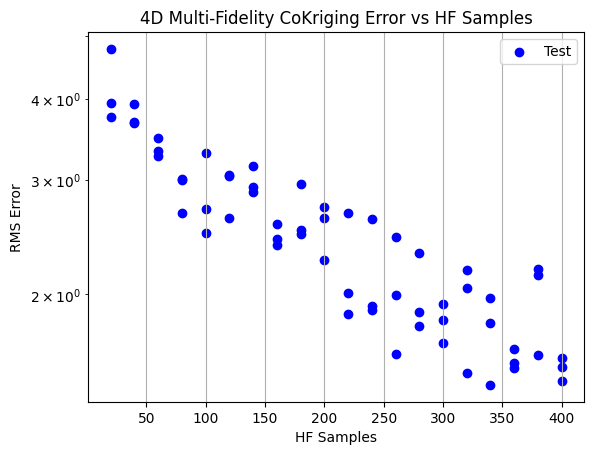

In [5]:
points_4d = []
model_error_4d = []
training_time_4d = []
evaluation_time_4d = []
points_4d, model_error_4d, evaluation_time_4d, training_time_4d = mf_kriging_helpers.generate_cokriging_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    n_lf=800,
    sample_low=20,
    sample_high=401,
    step_size=20,
    seeds=3,
    points=points_4d,
    model_error=model_error_4d,
    training_time=training_time_4d,
    evaluation_time=evaluation_time_4d,
    nugget=1e-3,
    output_file="cokriging_model_comparison_4d.csv",
)
ax = kriging_helpers.plot_error_measure(points_4d, model_error_4d, "4D Multi-Fidelity CoKriging Error vs HF Samples")
ax.set_xlabel("HF Samples")
kriging_helpers.save_plot(ax, "4D_sweep_cokriging")
plt.show()